In [1]:
%run ./template.ipynb

In [2]:
RNG = 42
np.random.seed(RNG)

TARGETS = {
    'Avg Temp': 'Average Annual Temperature (F)',
    'ToT Prcp': 'Total Annual Precipitation (in)',
    'Max Tmax': 'Hottest Day of the Year (F)',
    'cdd': 'Cooling Degree Days (F-days)',
}
TCOLS = list(TARGETS)
HORIZON = 7

# Story 1: research and select a method on a fixed temporal holdout.
RESEARCH_CONFIG = {
    "train_end_year": 2011,
    "test_start_year": 2012,
    "test_end_year": 2018,
    "forecast_origin": 2011,
    "training_max_horizon": HORIZON,
}

# Story 2: refit through 2018 and forecast the following seven years.
FINAL_CONFIG = {
    "train_end_year": 2018,
    "forecast_origin": 2018,
    "forecast_horizon": HORIZON,
}
FIRST_FORECAST_YEAR = FINAL_CONFIG["forecast_origin"] + 1

FEATURE_CONFIG = {
    "long_window": 30,
    "short_window": 10,
    "recent_window": 5,
    "min_long_slope_points": 15,
    "min_short_slope_points": 5,
}

assert RESEARCH_CONFIG["test_start_year"] == RESEARCH_CONFIG["train_end_year"] + 1
assert RESEARCH_CONFIG["forecast_origin"] == RESEARCH_CONFIG["train_end_year"]
assert FINAL_CONFIG["train_end_year"] == FINAL_CONFIG["forecast_origin"]

# 1. Load Data

In [3]:
REPO = "CMU-OSPO/protostar-climate-train-to-2018"
CACHE = Path('/tmp/annual.parquet')
if CACHE.exists():
  annual = pd.read_parquet(CACHE)
else:
  annual = load_dataset(REPO, "annual_indices", split="train").to_pandas()
cities = load_dataset(REPO, "city_info", split="train").to_pandas()
print(annual.shape, annual['Name'].nunique(), 'cities;', annual['Year'].min(), '-', annual['Year'].max())

(28052, 24) 210 cities; 1851 - 2018


# 2. Cleansing Missing

In [4]:
MISS_TOL = 60 # days; a year with >60 missing days (~16%) is not trusted

df = annual.copy()
df = df.replace([np.inf, -np.inf], np.nan)

bad_t = (df['Miss Tmax'] > MISS_TOL) | (df['Miss Tmin'] > MISS_TOL)
bad_p = df['Miss Prcp'] > MISS_TOL

audit = pd.DataFrame({
    'raw_nan': df[TCOLS].isna().sum(),
    'flagged_by_missing_days': pd.Series({
        'Avg Temp': int(bad_t.sum()), 'Max Tmax': int(bad_t.sum()),
        'cdd': int(bad_t.sum()), 'ToT Prcp': int(bad_p.sum())}),
    })
display(audit)

for c in ['Avg Temp', 'Max Tmax', 'cdd']:
  df.loc[bad_t, c] = np.nan
df.loc[bad_p, 'ToT Prcp'] = np.nan

df = df.sort_values(['Name', 'Year']).reset_index(drop=True)
print('NaN after cleaning:'); display(df[TCOLS].isna().sum().to_frame('nan_count'))
print('Rows with all four targets valid:', int(df[TCOLS].notna().all(axis=1).sum()), 'of', len(df))

,raw_nan,flagged_by_missing_days
Avg Temp,1193,1902
Max Tmax,1184,1902
ToT Prcp,0,1858
cdd,1206,1902


NaN after cleaning:


,nan_count
Avg Temp,1902
ToT Prcp,1858
Max Tmax,1902
cdd,1902


Rows with all four targets valid: 25714 of 28052


# 3. Baseline Model

In [5]:
# Wide matrices: rows = years, columns = cities
YEARS = np.arange(df.Year.min(), 2019)
CITIES = sorted(df.Name.unique())
W = {
    c: df.pivot(index='Year', columns='Name', values=c).reindex(index=YEARS, columns=CITIES)
    for c in TCOLS
}
META = df.groupby('Name')[['Lat', 'Lon']].first().reindex(CITIES)

# display(YEARS)
# display(CITIES)
# display(W)
# display(META)

In [6]:
def last_valid(M, T):
    """Most recent non-NaN value at or before year T, per city."""
    return M.loc[:T].ffill().iloc[-1]


def baseline_last_year(M, T):
    return last_valid(M, T)


def baseline_avg30(M, T):
    return M.loc[T - 29:T].mean()


def baseline_trend30(M, T, min_pts=15):
    sub = M.loc[T - 29:T]
    x = sub.index.values.astype(float)
    out = {}
    for city in sub.columns:
        y = sub[city].values
        ok = ~np.isnan(y)
        if ok.sum() >= min_pts:
            out[city] = np.polyfit(x[ok], y[ok], 1)
        else:
            out[city] = (0.0, np.nan)
    return pd.Series(out)


def trend30_forecast(M, T, h, coefs=None):
    coefs = baseline_trend30(M, T) if coefs is None else coefs
    return pd.Series({city: coefs[city][0] * (T + h) + coefs[city][1] for city in M.columns})


# Sanity check at the 2018 forecast origin for one city.
for metric in TCOLS:
    print(
        metric,
        '| Aberdeen 2018 last-year=%.1f avg30=%.1f trend30(2019)=%.1f' % (
            baseline_last_year(W[metric], 2018)['Aberdeen'],
            baseline_avg30(W[metric], 2018)['Aberdeen'],
            trend30_forecast(W[metric], 2018, 1)['Aberdeen'],
        ),
    )

Avg Temp | Aberdeen 2018 last-year=43.2 avg30=43.7 trend30(2019)=44.1
ToT Prcp | Aberdeen 2018 last-year=17.9 avg30=21.7 trend30(2019)=19.9
Max Tmax | Aberdeen 2018 last-year=100.9 avg30=98.1 trend30(2019)=99.0
cdd | Aberdeen 2018 last-year=820.9 avg30=579.7 trend30(2019)=618.0


In [7]:
ORIGINS = list(range(1995, 2012))  # T + 7 <= 2018


def run_baselines(origins=ORIGINS):
    records = []
    for metric in TCOLS:
        matrix = W[metric]
        for origin in origins:
            last_year = baseline_last_year(matrix, origin)
            avg30 = baseline_avg30(matrix, origin)
            coefs = baseline_trend30(matrix, origin)
            for horizon in range(1, HORIZON + 1):
                actual = matrix.loc[origin + horizon]
                trend = trend30_forecast(matrix, origin, horizon, coefs)
                records.append(pd.DataFrame({
                    'target': metric,
                    'origin': origin,
                    'h': horizon,
                    'city': CITIES,
                    'y': actual.values,
                    'Last Year': last_year.values,
                    '30-Yr Avg': avg30.values,
                    'Linear Trend': trend.values,
                }))
    return pd.concat(records, ignore_index=True)


bt = run_baselines()
print(bt.shape)
BASE = ['Last Year', '30-Yr Avg', 'Linear Trend']

def mae_table(frame, methods, by=None):
    scored = frame.dropna(subset=['y'] + methods)
    groups = scored.groupby(by) if by else scored.assign(_all=1).groupby('_all')
    return groups.apply(
        lambda data: pd.Series({
            method: np.mean(np.abs(data[method] - data['y']))
            for method in methods
        })
    )


res_base = mae_table(bt, BASE, by='target').loc[TCOLS]
display(res_base.round(3))

(99960, 8)


,Last Year,30-Yr Avg,Linear Trend
target,,,
Avg Temp,1.443,1.303,1.173
ToT Prcp,7.895,5.829,6.183
Max Tmax,3.538,2.625,2.824
cdd,209.866,180.578,170.747


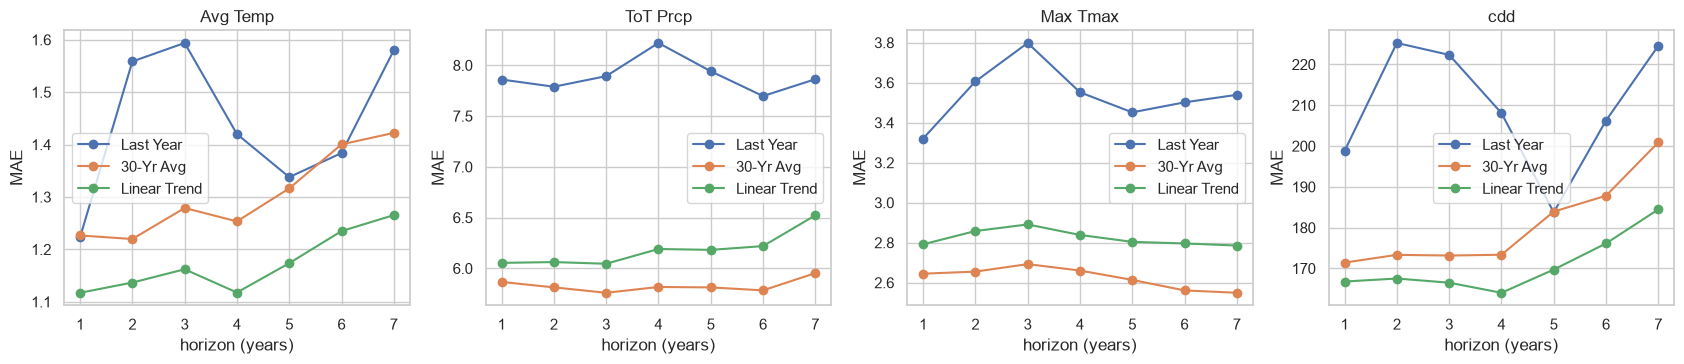

In [8]:
# MAE by forecast horizon: does the ranking of baselines change with lead time?
by_h = mae_table(bt, BASE, by=['target', 'h'])
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, c in zip(axes, TCOLS):
    by_h.loc[c].plot(ax=ax, marker='o')
    ax.set_title(c); ax.set_xlabel('horizon (years)'); ax.set_ylabel('MAE')
plt.tight_layout(); plt.show()

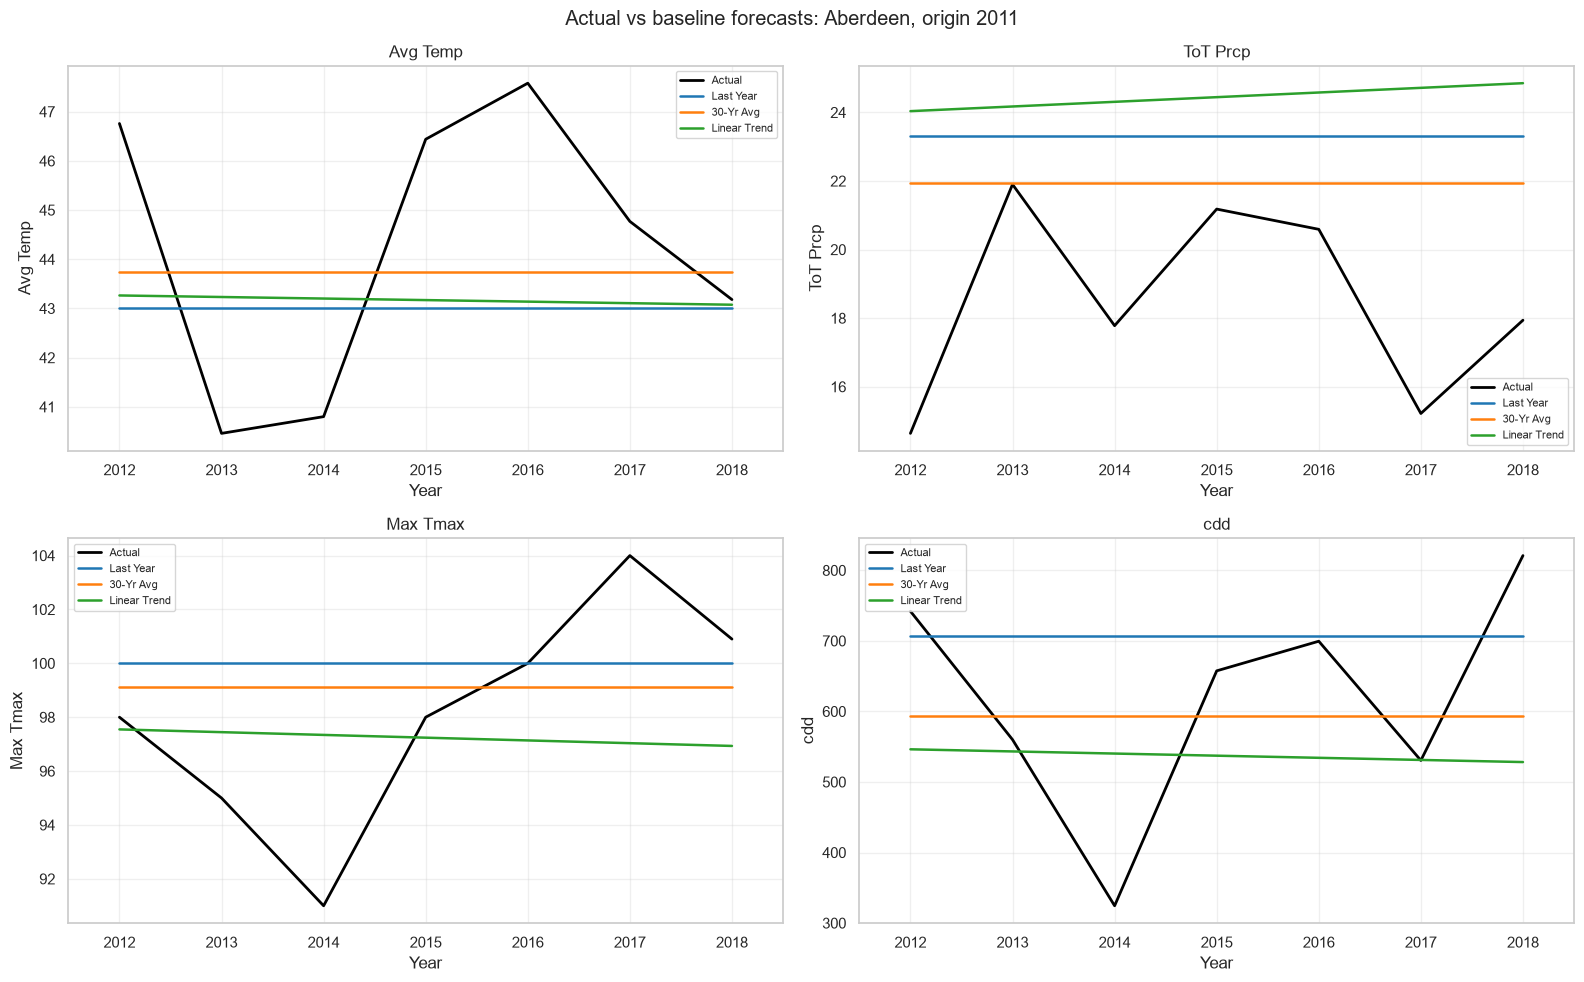

In [9]:
# Compare validation observations with forecasts made at the 2011 origin.
CITY_TO_PLOT = 'Aberdeen'
ORIGIN_TO_PLOT = 2011
VALIDATION_YEARS = range(ORIGIN_TO_PLOT + 1, ORIGIN_TO_PLOT + HORIZON + 1)

actual_validation = df.loc[
    (df['Name'] == CITY_TO_PLOT)
    & df['Year'].isin(VALIDATION_YEARS),
    ['Year'] + TCOLS,
].sort_values('Year')

city_forecasts = bt.loc[
    (bt['city'] == CITY_TO_PLOT)
    & (bt['origin'] == ORIGIN_TO_PLOT),
].copy()
city_forecasts['forecast_year'] = city_forecasts['origin'] + city_forecasts['h']

forecast_colors = {
    'Last Year': 'tab:blue',
    '30-Yr Avg': 'tab:orange',
    'Linear Trend': 'tab:green',
}

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, metric in zip(axes.ravel(), TCOLS):
    actual_metric = actual_validation.dropna(subset=[metric])
    ax.plot(
        actual_metric['Year'].to_numpy(),
        actual_metric[metric].to_numpy(),
        color='black', linewidth=2, label='Actual',
    )

    metric_forecasts = city_forecasts.loc[
        city_forecasts['target'] == metric
    ].sort_values('forecast_year')
    for method, color in forecast_colors.items():
        forecast_values = metric_forecasts.dropna(subset=[method])
        ax.plot(
            forecast_values['forecast_year'].to_numpy(),
            forecast_values[method].to_numpy(),
            color=color, linewidth=1.8, label=method,
        )

    ax.set_xlim(ORIGIN_TO_PLOT + 0.5, ORIGIN_TO_PLOT + HORIZON + 0.5)
    ax.set_xticks(list(VALIDATION_YEARS))
    ax.set_title(metric)
    ax.set_xlabel('Year')
    ax.set_ylabel(metric)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

fig.suptitle(f'Actual vs baseline forecasts: {CITY_TO_PLOT}, origin {ORIGIN_TO_PLOT}')
plt.tight_layout()
plt.show()

# 4. Model Chalengger

## Feture Engineering

### ==========================================
### CONTEXT 2: SPATIAL KERNEL & DISTANCE MATRIX
### ==========================================
Fungsi: Menghitung jarak antar kota menggunakan formula Haversine dan membangun Gaussian Spatial Kernel agar kota-kota yang berdekatan dapat saling berbagi informasi tren iklim regional.

In [10]:
def build_spatial_kernel(cities_df, bandwidth_km=450.0):
    """Membangun matriks bobot spasial Gaussian berdasarkan koordinat Lat/Lon kota."""
    coords_df = (
        cities_df.groupby("Name", as_index=False)
        .agg({"Lat": "first", "Lon": "first"})
        .sort_values("Name")
        .reset_index(drop=True)
    )
    
    city_list = coords_df["Name"].tolist()
    coords_rad = np.radians(coords_df[["Lat", "Lon"]].to_numpy())
    
    # Hitung jarak Haversine antar seluruh kota (dalam km)
    lat1, lon1 = coords_rad[:, 0:1], coords_rad[:, 1:2]
    lat2, lon2 = coords_rad[:, 0:1].T, coords_rad[:, 1:2].T
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2
    dist_km = 6371.0 * (2.0 * np.arcsin(np.sqrt(np.clip(a, 0.0, 1.0))))
    
    # Gaussian Kernel Matrix
    spatial_weights = np.exp(-0.5 * (dist_km / bandwidth_km) ** 2)
    spatial_weights /= spatial_weights.sum(axis=1, keepdims=True)
    
    return city_list, spatial_weights, coords_df

# Eksekusi Konteks 2
CITIES_LIST, SPATIAL_WEIGHTS, META_CITIES = build_spatial_kernel(cities)
print(f"Spatial weights matrix shape: {SPATIAL_WEIGHTS.shape}")

Spatial weights matrix shape: (210, 210)


### ==========================================
### CONTEXT 3: CHALLENGER FEATURE EXTRACTION
### ==========================================
Fungsi: Mengekstrak fitur canggih untuk Challenger Model, mencakup tren jangka pendek (10 tahun terakhir), tren jangka panjang (30 tahun), sensitivitas fisik termal ($\partial \text{CDD} / \partial T$), dan perbaikan anomali stasiun.

In [11]:
def extract_challenger_features(
    df_clean,
    cities_list,
    as_of_year=2018,
    long_window=30,
    short_window=10,
    min_pairs=5,
):
    """Build one city feature snapshot using observations no later than as_of_year."""
    features_list = []
    long_start = as_of_year - long_window + 1
    short_start = as_of_year - short_window + 1

    for city in cities_list:
        city_data = df_clean[df_clean['Name'] == city].sort_values('Year')
        long_data = city_data[city_data['Year'].between(long_start, as_of_year)]
        short_data = city_data[city_data['Year'].between(short_start, as_of_year)]
        avg_temp_long = long_data['Avg Temp'].mean()
        avg_temp_short = short_data['Avg Temp'].mean()

        paired = long_data[['Avg Temp', 'cdd']].dropna()
        if len(paired) >= min_pairs and paired['Avg Temp'].std() > 1e-4:
            cdd_sensitivity = np.clip(
                np.polyfit(paired['Avg Temp'], paired['cdd'], 1)[0],
                10.0,
                220.0,
            )
        else:
            cdd_sensitivity = 60.0

        features_list.append({
            'Name': city,
            'as_of_year': as_of_year,
            'avg_temp_long': avg_temp_long,
            'avg_temp_short': avg_temp_short,
            'temp_acceleration': avg_temp_short - avg_temp_long,
            'cdd_thermal_sensitivity': cdd_sensitivity,
        })

    return pd.DataFrame(features_list)


challenger_features_df = extract_challenger_features(
    df,
    CITIES_LIST,
    as_of_year=FINAL_CONFIG['forecast_origin'],
    long_window=FEATURE_CONFIG['long_window'],
    short_window=FEATURE_CONFIG['short_window'],
)
display(challenger_features_df.head())

,Name,as_of_year,avg_temp_long,avg_temp_short,temp_acceleration,cdd_thermal_sensitivity
0,Aberdeen,2018,43.708667,43.8340,0.125333,32.319650
1,Abilene,2018,65.101000,65.8850,0.784000,220.000000
2,Aiken,2018,64.471600,64.1125,-0.359100,176.552583
3,Akron,2018,51.165263,51.6170,0.451737,122.009615
4,Albany,2018,48.987333,49.8340,0.846667,77.220034


### ==========================================
### CONTEXT 4: MULTI-SCALE TEMPORAL ACCELERATION
### ==========================================
untuk menangkap apakah sebuah kota mengalami percepatan pemanasan/perubahan iklim (misalnya: apakah laju kenaikan suhu dalam 10 tahun terakhir jauh lebih cepat dibandingkan laju tren dalam 30 tahun penuh).

In [12]:
def extract_multiscale_temporal_features(
    df_clean,
    cities_list,
    targets,
    as_of_year=2018,
    long_window=30,
    short_window=10,
    recent_window=5,
    min_long_slope_points=15,
    min_short_slope_points=5,
):
    """Build multiscale trend features using only observations through as_of_year."""
    features = []
    long_start = as_of_year - long_window + 1
    short_start = as_of_year - short_window + 1
    recent_start = as_of_year - recent_window + 1

    for city in cities_list:
        city_data = df_clean[df_clean['Name'] == city].sort_values('Year')
        row_features = {'Name': city, 'as_of_year': as_of_year}

        for target in targets:
            long_data = city_data[
                city_data['Year'].between(long_start, as_of_year)
            ]
            short_data = city_data[
                city_data['Year'].between(short_start, as_of_year)
            ]
            recent_data = city_data[
                city_data['Year'].between(recent_start, as_of_year)
            ]

            long_years = long_data['Year'].to_numpy(dtype=float)
            long_values = long_data[target].to_numpy(dtype=float)
            valid_long = np.isfinite(long_values)
            slope_long = (
                np.polyfit(long_years[valid_long], long_values[valid_long], 1)[0]
                if valid_long.sum() >= min_long_slope_points else np.nan
            )

            short_years = short_data['Year'].to_numpy(dtype=float)
            short_values = short_data[target].to_numpy(dtype=float)
            valid_short = np.isfinite(short_values)
            slope_short = (
                np.polyfit(short_years[valid_short], short_values[valid_short], 1)[0]
                if valid_short.sum() >= min_short_slope_points else np.nan
            )

            mean_long = long_data[target].mean()
            mean_recent = recent_data[target].mean()
            acceleration = (
                slope_short - slope_long
                if np.isfinite(slope_short) and np.isfinite(slope_long)
                else np.nan
            )
            recent_anomaly = (
                mean_recent - mean_long
                if np.isfinite(mean_recent) and np.isfinite(mean_long)
                else 0.0
            )

            prefix = target.replace(' ', '_').lower()
            row_features[f'{prefix}_slope_long'] = slope_long
            row_features[f'{prefix}_slope_short'] = slope_short
            row_features[f'{prefix}_acceleration'] = acceleration
            row_features[f'{prefix}_recent_anomaly'] = recent_anomaly

        features.append(row_features)

    return pd.DataFrame(features)


multiscale_features_df = extract_multiscale_temporal_features(
    df,
    CITIES_LIST,
    TCOLS,
    as_of_year=FINAL_CONFIG['forecast_origin'],
    long_window=FEATURE_CONFIG['long_window'],
    short_window=FEATURE_CONFIG['short_window'],
    recent_window=FEATURE_CONFIG['recent_window'],
    min_long_slope_points=FEATURE_CONFIG['min_long_slope_points'],
    min_short_slope_points=FEATURE_CONFIG['min_short_slope_points'],
)
print("Shape fitur multi-skala:", multiscale_features_df.shape)
display(multiscale_features_df.head())

Shape fitur multi-skala: (210, 18)


,Name,as_of_year,avg_temp_slope_long,avg_temp_slope_short,avg_temp_acceleration,avg_temp_recent_anomaly,tot_prcp_slope_long,tot_prcp_slope_short,tot_prcp_acceleration,tot_prcp_recent_anomaly,max_tmax_slope_long,max_tmax_slope_short,max_tmax_acceleration,max_tmax_recent_anomaly,cdd_slope_long,cdd_slope_short,cdd_acceleration,cdd_recent_anomaly
0,Aberdeen,2018,0.024516,0.266909,0.242393,0.845333,-0.115250,-0.842424,-0.727174,-3.112333,0.056307,0.582424,0.526117,0.650000,2.465539,20.294545,17.829006,26.833333
1,Abilene,2018,0.065439,-0.051455,-0.116894,0.553000,0.037691,1.258000,1.220309,3.927333,0.041824,-0.296970,-0.338794,-0.333333,14.616051,-29.683939,-44.299991,106.291667
2,Aiken,2018,-0.016393,0.239722,0.256115,-0.023600,-0.229541,-0.213056,0.016485,-0.872400,-0.174196,-0.152778,0.021418,-2.280000,-3.149461,10.520833,13.670295,-66.980000
3,Akron,2018,0.134316,0.354121,0.219805,1.180737,-0.107842,-0.808364,-0.700522,-4.575474,0.185789,0.223636,0.037847,0.446316,24.470614,53.922727,29.452113,209.942105
4,Albany,2018,0.074478,0.120606,0.046128,0.922667,0.140198,-0.344667,-0.484865,-1.473667,0.052280,0.048485,-0.003795,-0.100000,9.728799,31.130000,21.401201,156.825000


## Two-stage challenger experiment

**Research:** train on target years through 2010 and test on 2011-2018 from origin 2010. Compare the three baselines with the LightGBM challenger and select the lowest-MAE method per target.

**Final forecast:** refit the selected method using observations through 2018, then forecast 2019-2025. `RESEARCH_CONFIG`, `FINAL_CONFIG`, and `FEATURE_CONFIG` control the two stages separately.

In [26]:
from lightgbm import LGBMRegressor

# Align the spatial-weight matrix with the city order used by W and CITIES.
CHALLENGER_WEIGHTS = (
    pd.DataFrame(SPATIAL_WEIGHTS, index=CITIES_LIST, columns=CITIES_LIST)
    .reindex(index=CITIES, columns=CITIES)
    .to_numpy(dtype=float)
)
if not np.isfinite(CHALLENGER_WEIGHTS).all():
    raise ValueError("SPATIAL_WEIGHTS and CITIES do not contain the same city names.")

BASE_CHALLENGER_FEATURES = [
    "city", "h", "lat", "lon", "last_value", "years_since_last",
    "mean5", "mean10", "mean30", "std30", "slope10", "slope30",
    "acceleration", "recent_anomaly", "spatial_anomaly",
    "baseline_avg30",
]
CITY_CATEGORY = pd.CategoricalDtype(categories=CITIES)


def weighted_spatial_mean(values):
    values = np.asarray(values, dtype=float)
    valid = np.isfinite(values)
    if not valid.any():
        return np.full(len(CITIES), np.nan)
    weights = CHALLENGER_WEIGHTS[:, valid]
    weight_totals = weights.sum(axis=1)
    weighted_totals = weights @ values[valid]
    return np.divide(
        weighted_totals,
        weight_totals,
        out=np.full(len(CITIES), np.nan),
        where=weight_totals > 0,
    )


def rolling_slope(history, min_points):
    slopes = {}
    years = history.index.to_numpy(dtype=float)
    for city in CITIES:
        values = history[city].to_numpy(dtype=float)
        valid = np.isfinite(values)
        slopes[city] = (
            np.polyfit(years[valid], values[valid], 1)[0]
            if valid.sum() >= min_points else np.nan
        )
    return pd.Series(slopes, index=CITIES, dtype=float)


def build_origin_engineered_features(as_of_year):
    challenger_snapshot = extract_challenger_features(
        df,
        CITIES_LIST,
        as_of_year=as_of_year,
        long_window=FEATURE_CONFIG["long_window"],
        short_window=FEATURE_CONFIG["short_window"],
    )
    multiscale_snapshot = extract_multiscale_temporal_features(
        df,
        CITIES_LIST,
        TCOLS,
        as_of_year=as_of_year,
        long_window=FEATURE_CONFIG["long_window"],
        short_window=FEATURE_CONFIG["short_window"],
        recent_window=FEATURE_CONFIG["recent_window"],
        min_long_slope_points=FEATURE_CONFIG["min_long_slope_points"],
        min_short_slope_points=FEATURE_CONFIG["min_short_slope_points"],
    )

    challenger_columns = {
        column: f"challenger_{column}"
        for column in challenger_snapshot.columns
        if column not in {"Name", "as_of_year"}
    }
    multiscale_columns = {
        column: f"multiscale_{column}"
        for column in multiscale_snapshot.columns
        if column not in {"Name", "as_of_year"}
    }
    merged = challenger_snapshot.rename(columns=challenger_columns).merge(
        multiscale_snapshot.rename(columns=multiscale_columns),
        on="Name",
        how="inner",
        validate="one_to_one",
    )
    return merged.set_index("Name")


def build_challenger_panel(metric, origins, max_horizon, engineered_by_origin):
    feature_config = FEATURE_CONFIG
    matrix = W[metric].reindex(index=YEARS, columns=CITIES)
    temperature = W["Avg Temp"].reindex(index=YEARS, columns=CITIES)
    cdd_matrix = W["cdd"].reindex(index=YEARS, columns=CITIES)
    long_window = feature_config["long_window"]
    short_window = feature_config["short_window"]
    recent_window = feature_config["recent_window"]
    records = []

    for origin in origins:
        origin_features = engineered_by_origin[origin]
        history = matrix.loc[origin - long_window + 1:origin]
        short_history = matrix.loc[origin - short_window + 1:origin]
        recent_history = matrix.loc[origin - recent_window + 1:origin]
        mean_long = history.mean()
        mean_short = short_history.mean()
        mean_recent = recent_history.mean()
        std_long = history.std()
        last_values = history.ffill().iloc[-1]
        last_years = pd.Series(
            {city: history[city].last_valid_index() for city in CITIES},
            index=CITIES,
            dtype=float,
        )
        slope_long = rolling_slope(history, feature_config["min_long_slope_points"])
        slope_short = rolling_slope(short_history, feature_config["min_short_slope_points"])
        spatial_anomaly = weighted_spatial_mean((last_values - mean_long).to_numpy())

        temp_history = temperature.loc[origin - long_window + 1:origin]
        cdd_history = cdd_matrix.loc[origin - long_window + 1:origin]
        thermal_sensitivity = {}
        for city in CITIES:
            paired = pd.concat(
                [temp_history[city].rename("temp"), cdd_history[city].rename("cdd")],
                axis=1,
            ).dropna()
            if len(paired) >= 5 and paired["temp"].std() > 1e-4:
                thermal_sensitivity[city] = np.clip(
                    np.polyfit(paired["temp"], paired["cdd"], 1)[0], 10.0, 220.0
                )
            else:
                thermal_sensitivity[city] = 60.0

        for horizon in range(1, max_horizon + 1):
            target_year = origin + horizon
            for city_index, city in enumerate(CITIES):
                actual = (
                    matrix.at[target_year, city]
                    if target_year in matrix.index else np.nan
                )
                engineered_features = origin_features.loc[city].to_dict()
                records.append({
                    "target": metric,
                    "city": city,
                    "origin": origin,
                    "h": horizon,
                    "target_year": target_year,
                    "y": actual,
                    "last_value": last_values[city],
                    "years_since_last": origin - last_years[city],
                    "mean5": mean_recent[city],
                    "mean10": mean_short[city],
                    "mean30": mean_long[city],
                    "std30": std_long[city],
                    "slope10": slope_short[city],
                    "slope30": slope_long[city],
                    "acceleration": slope_short[city] - slope_long[city],
                    "recent_anomaly": mean_recent[city] - mean_long[city],
                    "spatial_anomaly": spatial_anomaly[city_index],
                    "cdd_thermal_sensitivity": thermal_sensitivity[city],
                    "baseline_avg30": mean_long[city],
                    "lat": META.loc[city, "Lat"],
                    "lon": META.loc[city, "Lon"],
                    **engineered_features,
                })

    panel = pd.DataFrame(records)
    panel["city"] = panel["city"].astype(CITY_CATEGORY)
    return panel


# Recompute both engineered feature tables at every origin to prevent leakage.
feature_origin_start = max(
    int(YEARS.min()) + FEATURE_CONFIG["long_window"] - 1,
    1950,
)
feature_origins = list(range(
    feature_origin_start,
    FINAL_CONFIG["forecast_origin"] + 1,
))
ORIGIN_ENGINEERED_FEATURES = {
    origin: build_origin_engineered_features(origin)
    for origin in feature_origins
}

# Keep the existing feature-table names as the final-origin snapshots.
challenger_features_df = extract_challenger_features(
    df,
    CITIES_LIST,
    as_of_year=FINAL_CONFIG["forecast_origin"],
    long_window=FEATURE_CONFIG["long_window"],
    short_window=FEATURE_CONFIG["short_window"],
)
multiscale_features_df = extract_multiscale_temporal_features(
    df,
    CITIES_LIST,
    TCOLS,
    as_of_year=FINAL_CONFIG["forecast_origin"],
    long_window=FEATURE_CONFIG["long_window"],
    short_window=FEATURE_CONFIG["short_window"],
    recent_window=FEATURE_CONFIG["recent_window"],
    min_long_slope_points=FEATURE_CONFIG["min_long_slope_points"],
    min_short_slope_points=FEATURE_CONFIG["min_short_slope_points"],
)

engineered_feature_columns = list(
    ORIGIN_ENGINEERED_FEATURES[feature_origin_start].columns
)
CHALLENGER_FEATURES = BASE_CHALLENGER_FEATURES + engineered_feature_columns

research_validation_horizon = (
    RESEARCH_CONFIG["test_end_year"] - RESEARCH_CONFIG["forecast_origin"]
)
panel_max_horizon = max(
    FINAL_CONFIG["forecast_horizon"],
    research_validation_horizon,
)
CHALLENGER_PANEL = {
    metric: build_challenger_panel(
        metric,
        feature_origins,
        max_horizon=panel_max_horizon,
        engineered_by_origin=ORIGIN_ENGINEERED_FEATURES,
    )
    for metric in TCOLS
}
for panel in CHALLENGER_PANEL.values():
    panel["city"] = panel["city"].astype(object)

print("Engineered features added:", len(engineered_feature_columns))
print("Challenger features total:", len(CHALLENGER_FEATURES))
print({metric: panel.shape for metric, panel in CHALLENGER_PANEL.items()})

Engineered features added: 22
Challenger features total: 38
{'Avg Temp': (101430, 43), 'ToT Prcp': (101430, 43), 'Max Tmax': (101430, 43), 'cdd': (101430, 43)}


In [27]:
from catboost import CatBoostRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

FEATS = [
    "ly_a", "a5_a", "a10_a", "trend_off", "slope", "sd30",
    "lat", "lon", "h", "a30", "nat_ly", "nat_a5",
]
CHALLENGER_FEATURES = list(dict.fromkeys(CHALLENGER_FEATURES + FEATS))
RIDGE_FEATURES_TO_FILL = [feature for feature in FEATS if feature != "h"]


def build_baseline_features(M, T, h):
    """Build city-level baseline and spatial-context features using data through T."""
    long_window = FEATURE_CONFIG["long_window"]
    short_window = FEATURE_CONFIG["short_window"]
    recent_window = FEATURE_CONFIG["recent_window"]

    a30 = M.loc[T - long_window + 1:T].mean()
    a10 = M.loc[T - short_window + 1:T].mean()
    a5 = M.loc[T - recent_window + 1:T].mean()
    ly = baseline_last_year(M, T)
    sd30 = M.loc[T - long_window + 1:T].std()
    coefs = baseline_trend30(M, T)
    slope = pd.Series(
        {city: coefs[city][0] for city in M.columns},
        index=M.columns,
        dtype=float,
    )
    trend = trend30_forecast(M, T, h, coefs)
    nat_ly = (ly - a30).mean()
    nat_a5 = (a5 - a30).mean()

    return pd.DataFrame({
        "city": M.columns,
        "ly_a": (ly - a30).to_numpy(),
        "a5_a": (a5 - a30).to_numpy(),
        "a10_a": (a10 - a30).to_numpy(),
        "trend_off": (trend - a30).to_numpy(),
        "slope": slope.to_numpy(),
        "sd30": sd30.to_numpy(),
        "lat": META.loc[M.columns, "Lat"].to_numpy(dtype=float),
        "lon": META.loc[M.columns, "Lon"].to_numpy(dtype=float),
        "h": h,
        "a30": a30.to_numpy(),
        "nat_ly": nat_ly,
        "nat_a5": nat_a5,
    })


def add_baseline_features_to_panels(panels):
    enriched_panels = {}
    for metric, source_panel in panels.items():
        feature_panel = source_panel.copy()
        feature_panel["city"] = feature_panel["city"].astype(object)
        feature_panel["origin"] = pd.to_numeric(feature_panel["origin"], errors="coerce")
        feature_panel["h"] = pd.to_numeric(feature_panel["h"], errors="coerce")
        finite_keys = np.isfinite(
            feature_panel[["origin", "h"]].to_numpy(dtype=float)
        ).all(axis=1)
        if not finite_keys.all():
            print(
                f"{metric}: dropping {int((~finite_keys).sum())} rows "
                "with non-finite origin/horizon."
            )
            feature_panel = feature_panel.loc[finite_keys].copy()
        if feature_panel.empty:
            raise ValueError(
                f"{metric} challenger panel is empty; rerun the panel-building cell first."
            )

        feature_panel[RIDGE_FEATURES_TO_FILL] = np.nan
        matrix = W[metric]
        for origin in sorted(feature_panel["origin"].unique()):
            origin_rows = feature_panel["origin"].eq(origin)
            horizons = sorted(feature_panel.loc[origin_rows, "h"].unique())
            for horizon in horizons:
                target_rows = origin_rows & feature_panel["h"].eq(horizon)
                city_names = feature_panel.loc[target_rows, "city"]
                ridge_features = build_baseline_features(
                    matrix, int(origin), int(horizon)
                ).set_index("city")
                ridge_features = ridge_features.reindex(city_names)
                feature_panel.loc[target_rows, RIDGE_FEATURES_TO_FILL] = (
                    ridge_features[RIDGE_FEATURES_TO_FILL].to_numpy()
                )

                feature_panel.loc[target_rows, "Last Year"] = city_names.map(
                    baseline_last_year(matrix, int(origin))
                )
                average30 = baseline_avg30(matrix, int(origin))
                feature_panel.loc[target_rows, "30-Yr Avg"] = city_names.map(average30)
                feature_panel.loc[target_rows, "a30"] = city_names.map(average30)
                feature_panel.loc[target_rows, "Linear Trend"] = city_names.map(
                    trend30_forecast(matrix, int(origin), int(horizon))
                )

        feature_panel["Half-Trend"] = 0.5 * (
            feature_panel["30-Yr Avg"] + feature_panel["Linear Trend"]
        )
        enriched_panels[metric] = feature_panel

    return enriched_panels


CHALLENGER_PANEL = add_baseline_features_to_panels(CHALLENGER_PANEL)

Research split: train targets <= 2011; test targets 2012-2018 from origin 2011.
=== RESEARCH MAE: BASELINES, RIDGE, LIGHTGBM, CATBOOST, ENSEMBLE ===


,Last Year,30-Yr Avg,Linear Trend,Half-Trend,Ridge,LightGBM Challenger,CatBoost Challenger,Ensemble Challenger
target,,,,,,,,
Avg Temp,1.64,1.72,1.49,1.56,1.54,1.45,1.55,1.52
ToT Prcp,9.50,5.92,6.70,6.13,5.92,6.19,6.43,6.10
Max Tmax,4.48,2.42,2.54,2.40,2.36,3.51,3.42,2.68
cdd,217.66,207.48,167.55,178.56,164.91,168.07,182.95,163.64


=== SELECTED METHOD PER TARGET ===


,selected_method
target,
Avg Temp,LightGBM Challenger
ToT Prcp,Ridge
Max Tmax,Ridge
cdd,Ensemble Challenger


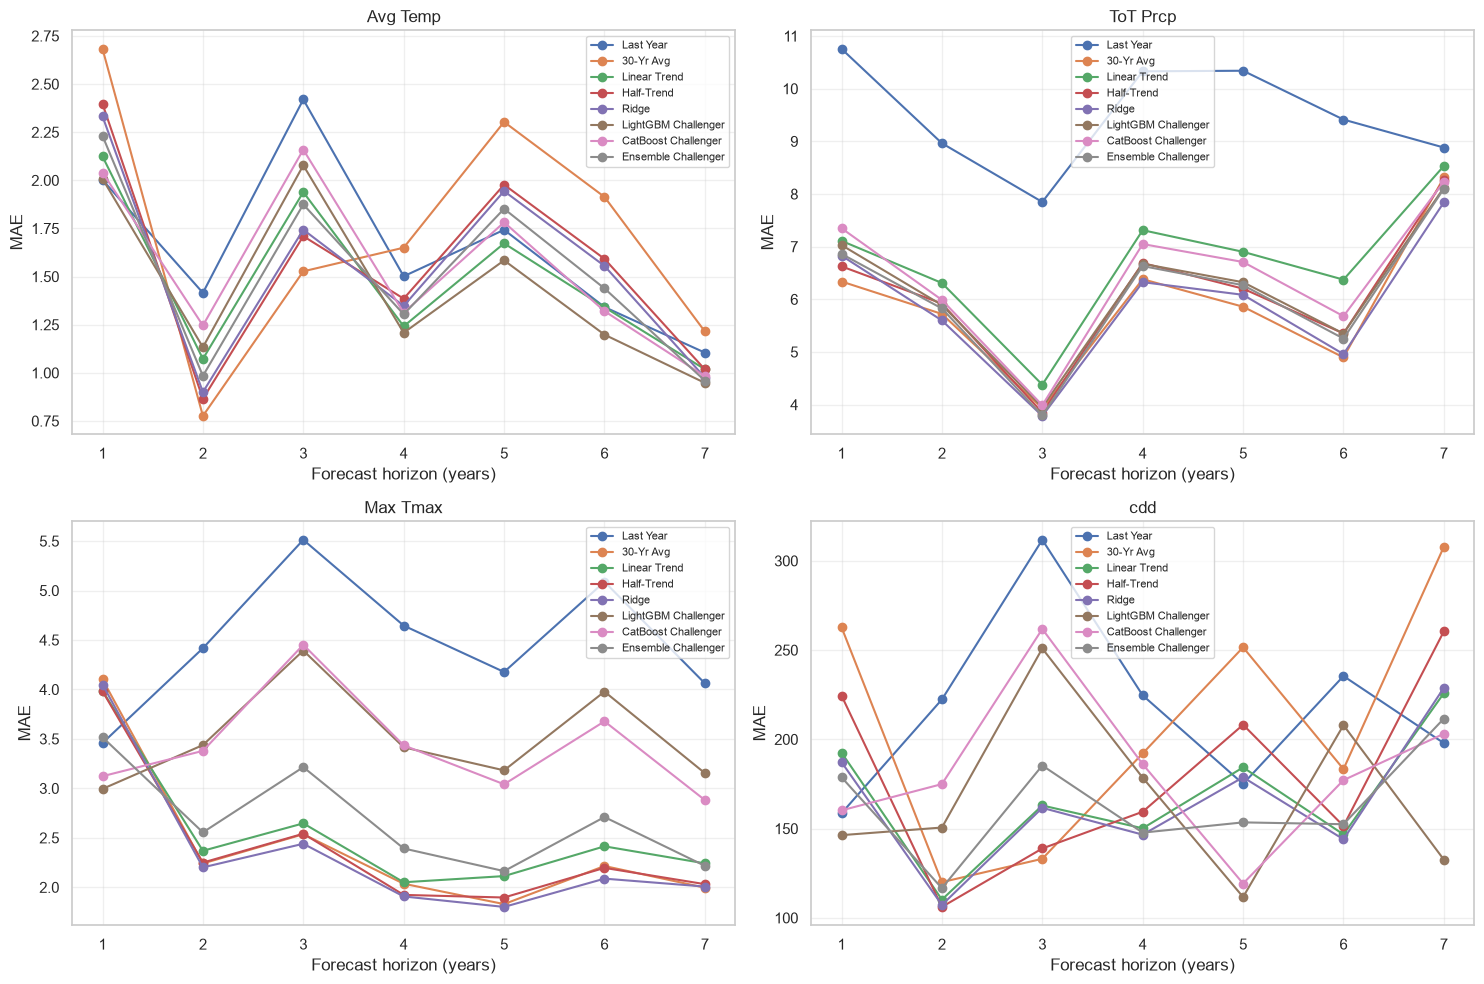

In [28]:
MODEL_METHODS = [
    "Ridge",
    "LightGBM Challenger",
    "CatBoost Challenger",
    "Ensemble Challenger",
]
TREE_FEATURES = CHALLENGER_FEATURES


def fit_residual_challenger(train, test):
    train = train.dropna(subset=["y", "a30"])
    test = test.dropna(subset=["a30"])
    if train.empty or test.empty:
        return pd.DataFrame(index=test.index, columns=MODEL_METHODS, dtype=float)

    residual = train["y"].to_numpy(dtype=float) - train["a30"].to_numpy(dtype=float)
    a30 = test["a30"].to_numpy(dtype=float)

    ridge = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        Ridge(alpha=10.0),
    )
    ridge.fit(train[FEATS], residual)
    predictions = {"Ridge": a30 + ridge.predict(test[FEATS])}

    lightgbm_train = train[TREE_FEATURES].copy()
    lightgbm_test = test[TREE_FEATURES].copy()
    lightgbm_train["city"] = pd.Categorical(lightgbm_train["city"], categories=CITIES)
    lightgbm_test["city"] = pd.Categorical(lightgbm_test["city"], categories=CITIES)
    lightgbm = LGBMRegressor(
        objective="regression_l1",
        n_estimators=250,
        learning_rate=0.04,
        num_leaves=15,
        min_child_samples=40,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=RNG,
        verbosity=-1,
        n_jobs=4,
    )
    lightgbm.fit(lightgbm_train, residual, categorical_feature=["city"])
    predictions["LightGBM Challenger"] = a30 + lightgbm.predict(lightgbm_test)

    catboost_train = train[TREE_FEATURES].copy()
    catboost_test = test[TREE_FEATURES].copy()
    catboost_train["city"] = catboost_train["city"].astype(str)
    catboost_test["city"] = catboost_test["city"].astype(str)
    catboost = CatBoostRegressor(
        loss_function="MAE",
        iterations=300,
        depth=6,
        learning_rate=0.04,
        l2_leaf_reg=3.0,
        random_seed=RNG,
        thread_count=4,
        verbose=False,
        allow_writing_files=False,
    )
    catboost.fit(catboost_train, residual, cat_features=["city"])
    predictions["CatBoost Challenger"] = a30 + catboost.predict(catboost_test)

    ensemble_members = [
        predictions["Ridge"],
        predictions["LightGBM Challenger"],
        predictions["CatBoost Challenger"],
        test["30-Yr Avg"].to_numpy(dtype=float),
        test["Linear Trend"].to_numpy(dtype=float),
    ]
    predictions["Ensemble Challenger"] = np.mean(
        np.column_stack(ensemble_members),
        axis=1,
    )
    return pd.DataFrame(predictions, index=test.index)


# Story 1: use only labels through train_end_year, then test the fixed holdout.
research = RESEARCH_CONFIG
train_end_year = research["train_end_year"]
test_start_year = research["test_start_year"]
test_end_year = research["test_end_year"]
research_origin = research["forecast_origin"]
training_max_horizon = research["training_max_horizon"]
research_test_horizon = test_end_year - research_origin

validation_baseline_records = []
for metric in TCOLS:
    matrix = W[metric]
    last_year = baseline_last_year(matrix, research_origin)
    avg30 = baseline_avg30(matrix, research_origin)
    coefs = baseline_trend30(matrix, research_origin)

    for horizon in range(1, research_test_horizon + 1):
        target_year = research_origin + horizon
        if not test_start_year <= target_year <= test_end_year:
            continue
        actual = matrix.loc[target_year]
        trend = trend30_forecast(matrix, research_origin, horizon, coefs)
        validation_baseline_records.append(pd.DataFrame({
            "target": metric,
            "origin": research_origin,
            "h": horizon,
            "target_year": target_year,
            "city": CITIES,
            "y": actual.values,
            "Last Year": last_year.values,
            "30-Yr Avg": avg30.values,
            "Linear Trend": trend.values,
            "Half-Trend": 0.5 * (avg30.values + trend.values),
        }))

validation_baselines = pd.concat(validation_baseline_records, ignore_index=True)
validation_predictions = []
for metric in TCOLS:
    panel = CHALLENGER_PANEL[metric]
    train = panel.loc[
        (panel["target_year"] <= train_end_year)
        & (panel["h"] <= training_max_horizon)
        & panel["y"].notna()
        & panel["a30"].notna()
    ]
    test = panel.loc[
        (panel["origin"] == research_origin)
        & panel["target_year"].between(test_start_year, test_end_year)
        & panel["y"].notna()
        & panel["a30"].notna()
    ].copy()
    if train.empty or test.empty:
        continue

    prediction = test[["target", "origin", "h", "target_year", "city"]].copy()
    model_predictions = fit_residual_challenger(train, test)
    for method in MODEL_METHODS:
        prediction[method] = model_predictions[method].to_numpy()
    validation_predictions.append(prediction)

validation_predictions = pd.concat(validation_predictions, ignore_index=True)
validation_results = validation_baselines.merge(
    validation_predictions,
    on=["target", "origin", "h", "target_year", "city"],
    how="inner",
    validate="one_to_one",
)

CHALLENGER_METHODS = BASE + ["Half-Trend"] + MODEL_METHODS
print(
    f"Research split: train targets <= {train_end_year}; "
    f"test targets {test_start_year}-{test_end_year} "
    f"from origin {research_origin}."
)
print("=== RESEARCH MAE: BASELINES, RIDGE, LIGHTGBM, CATBOOST, ENSEMBLE ===")
validation_mae = mae_table(
    validation_results, CHALLENGER_METHODS, by="target"
).reindex(TCOLS)
display(validation_mae.round(2))

BEST_METHOD_BY_TARGET = validation_mae.idxmin(axis=1)
print("=== SELECTED METHOD PER TARGET ===")
display(BEST_METHOD_BY_TARGET.to_frame("selected_method"))

validation_mae_by_horizon = mae_table(
    validation_results, CHALLENGER_METHODS, by=["target", "h"]
)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, metric in zip(axes.ravel(), TCOLS):
    metric_mae = validation_mae_by_horizon.loc[metric]
    for method in CHALLENGER_METHODS:
        ax.plot(metric_mae.index, metric_mae[method], marker="o", label=method)
    ax.set_title(metric)
    ax.set_xlabel("Forecast horizon (years)")
    ax.set_ylabel("MAE")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
# # Story 2: refit candidates through 2018, then apply the research-selected method.
# final_origin = FINAL_CONFIG["forecast_origin"]
# final_train_end_year = FINAL_CONFIG["train_end_year"]
# final_horizon = FINAL_CONFIG["forecast_horizon"]

# final_baseline_records = []
# for metric in TCOLS:
#     matrix = W[metric]
#     last_year = baseline_last_year(matrix, final_origin)
#     avg30 = baseline_avg30(matrix, final_origin)
#     coefs = baseline_trend30(matrix, final_origin)

#     for horizon in range(1, final_horizon + 1):
#         target_year = final_origin + horizon
#         trend = trend30_forecast(matrix, final_origin, horizon, coefs)
#         final_baseline_records.append(pd.DataFrame({
#             "target": metric,
#             "origin": final_origin,
#             "h": horizon,
#             "target_year": target_year,
#             "city": CITIES,
#             "Last Year": last_year.values,
#             "30-Yr Avg": avg30.values,
#             "Linear Trend": trend.values,
#             "Half-Trend": 0.5 * (avg30.values + trend.values),
#         }))

# final_baselines = pd.concat(final_baseline_records, ignore_index=True)
# final_candidate_predictions = []
# for metric in TCOLS:
#     panel = CHALLENGER_PANEL[metric]
#     train = panel.loc[
#         (panel["target_year"] <= final_train_end_year)
#         & (panel["h"] <= final_horizon)
#         & panel["y"].notna()
#         & panel["a30"].notna()
#     ]
#     test = panel.loc[
#         (panel["origin"] == final_origin)
#         & (panel["h"] <= final_horizon)
#         & panel["a30"].notna()
#     ].copy()
#     if train.empty or test.empty:
#         continue

#     prediction = test[["target", "origin", "h", "target_year", "city"]].copy()
#     model_predictions = fit_residual_challenger(train, test)
#     for method in MODEL_METHODS:
#         prediction[method] = model_predictions[method].to_numpy()
#     final_candidate_predictions.append(prediction)

# final_candidate_predictions = pd.concat(
#     final_candidate_predictions,
#     ignore_index=True,
# )
# final_candidate_forecasts = final_baselines.merge(
#     final_candidate_predictions,
#     on=["target", "origin", "h", "target_year", "city"],
#     how="left",
#     validate="one_to_one",
# )
# final_candidate_forecasts["selected_method"] = final_candidate_forecasts[
#     "target"
# ].map(BEST_METHOD_BY_TARGET)
# final_candidate_forecasts["forecast"] = final_candidate_forecasts.apply(
#     lambda row: row[row["selected_method"]],
#     axis=1,
# )

# challenger_forecast_final = final_candidate_forecasts[
#     [
#         "target", "city", "origin", "target_year", "h",
#         "selected_method", "forecast",
#     ]
# ].sort_values(["target", "city", "target_year"]).reset_index(drop=True)
# expected_forecasts = len(CITIES) * final_horizon * len(TCOLS)
# print(
#     f"Final fit through {final_train_end_year}; forecast years "
#     f"{final_origin + 1}-{final_origin + final_horizon}: "
#     f"{len(challenger_forecast_final)} / {expected_forecasts} rows",
# )
# print("Selected methods:")
# display(BEST_METHOD_BY_TARGET.to_frame("selected_method"))
# print("Missing final forecasts:", int(challenger_forecast_final["forecast"].isna().sum()))
# display(challenger_forecast_final.head(10))